[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/adkipnis/metabeta/blob/main/demos/02-families.ipynb)

# metabeta families: Bernoulli and Poisson

metabeta ships one pretrained checkpoint per likelihood family. This notebook fits a Bernoulli
GLMM to lme4's `cbpp` and a Poisson GLMM to glmmTMB's `Salamanders`, shows the submodel each
dataset is routed to and the posterior predictive check, and shows when the random-walk moves
matter: on the Poisson fit the independence Metropolis–Hastings (IMH) chains run out of distinct
states, and `random_walk=True` widens the intervals toward a NUTS reference. A CPU runtime is
enough; `01-quickstart` introduces the summary tables.

In [ ]:
%pip install -q metabeta==0.5.1 pyreadr

## Load the checkpoints

Each family has its own checkpoint on Hugging Face; `from_pretrained` downloads it on first use
and caches it. `pyreadr` reads R's `.rda` files without R and serves the Salamanders data below.

In [1]:
import numpy as np
import pandas as pd
import pyreadr
import statsmodels.api as sm
import torch

from metabeta import Api

device = 'cuda' if torch.cuda.is_available() else 'cpu'
mb_bernoulli = Api.from_pretrained('bernoulli', device=device)
mb_poisson = Api.from_pretrained('poisson', device=device)

Resolving metabeta 'bernoulli' checkpoint from Hugging Face (adkipnis/metabeta@v1)...


Using checkpoint: /Users/alex/.cache/huggingface/hub/models--adkipnis--metabeta/snapshots/66c398ef31d65400f9ce6cff262265a9cd895a4d/metabeta-bernoulli.pt


Loading metabeta checkpoint on cpu...


Metabeta checkpoint ready.


Resolving metabeta 'poisson' checkpoint from Hugging Face (adkipnis/metabeta@v1)...


Using checkpoint: /Users/alex/.cache/huggingface/hub/models--adkipnis--metabeta/snapshots/66c398ef31d65400f9ce6cff262265a9cd895a4d/metabeta-poisson.pt


Loading metabeta checkpoint on cpu...


Metabeta checkpoint ready.


## Bernoulli: cbpp

`cbpp` ([Lesnoff et al.](https://doi.org/10.1016/j.prevetmed.2004.03.005)) records the incidence
of contagious bovine pleuropneumonia in 15 Ethiopian zebu herds over four observation periods:
per herd and period, the number of new cases (`incidence`) among the animals at risk (`size`).
metabeta fits Bernoulli outcomes rather than binomial counts, so expand each herd-period into
one row per animal, `incidence` infected rows and `size − incidence` healthy ones; the
likelihood is the same up to a constant. `period` and `herd` arrive as integers. Cast them to
`str`, so that `period` is dummy-coded and `herd` stays a label. The most frequent level,
period 1, is the reference; R takes the first level, which here is the same one.

In [2]:
cbpp = sm.datasets.get_rdataset('cbpp', 'lme4').data
rows = cbpp.loc[cbpp.index.repeat(cbpp['size'])]
df_cbpp = pd.DataFrame(
    {
        'infected': (rows.groupby(level=0).cumcount() < rows['incidence']).astype(int).to_numpy(),
        'period': rows['period'].astype(str).to_numpy(),
        'herd': rows['herd'].astype(str).to_numpy(),
    }
)
herd_sizes = df_cbpp.groupby('herd').size()
print(f'{len(df_cbpp)} rows, {len(herd_sizes)} herds with {herd_sizes.min()}–{herd_sizes.max()} rows each')
df_cbpp.head()

842 rows, 15 herds with 26–96 rows each


,infected,period,herd
0,1,1,1
1,1,1,1
2,0,1,1
3,0,1,1
4,0,1,1


### Fit

The formula is lme4's: fixed effects of `period` and a random intercept per herd. The IMH chains
can only revisit the network's proposals, and their effective sample size (ESS) grows with the
number of draws. At the default of 1000 draws the smallest ESS of this fit sits near the
threshold of 150 at which `sample` warns; `n_samples=2000` clears it. `diagnostics=True` adds
the posterior predictive distribution and the fit metrics in the summary's footer.

In [3]:
%%time
torch.manual_seed(0)
result_cbpp = mb_bernoulli.sample(
    df_cbpp, formula='infected ~ period + (1 | herd)', n_samples=2000, diagnostics=True
)

CPU times: user 1.75 s, sys: 57.4 ms, total: 1.81 s
Wall time: 967 ms


### Routing

A checkpoint holds several submodels, trained for growing numbers of fixed and random effects.
`sample` routes each dataset to the smallest submodel that fits its design, and `result.routes`
names it, one entry per dataset:

In [4]:
result_cbpp.routes

['bernoulli-small']

### Posterior summary

The fixed effects are on the logit scale: the intercept is the log-odds of infection in the
first period for an average herd, and each `period_k` the change in log-odds in period k. The
posterior puts every later period below the first. With `diagnostics=True` the footer adds the
posterior predictive AUC, the leave-one-out negative log-likelihood (LOO-NLL) and its Pareto k,
next to the safeguards: the IMH acceptance and its minimum ESS, k̂ and the MAP distance.

In [5]:
print(mb_bernoulli.posteriorSummary(result_cbpp))

Formula:  infected ~ period + (1 | herd)
n = 842   m = 15
Priors:
  Intercept ~ N(0, 1.5)
  period_2 ~ N(0, 1)
  period_3 ~ N(0, 1)
  period_4 ~ N(0, 1)
  σ_Intercept ~ HN(2.5)

Fixed Effects:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |   P(>0) |   Contr. |
|-----------|--------|-------|--------|---------|---------|---------|----------|
| Intercept | -1.430 | 0.255 | -1.972 |  -1.442 |  -0.983 |   0.000 |    0.971 |
| period_2  | -0.875 | 0.290 | -1.428 |  -0.878 |  -0.300 |   0.002 |    0.916 |
| period_3  | -0.998 | 0.312 | -1.631 |  -0.992 |  -0.401 |   0.000 |    0.903 |
| period_4  | -1.341 | 0.384 | -2.198 |  -1.304 |  -0.700 |   0.000 |    0.852 |

Standard Deviations:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |
|-----------|--------|-------|--------|---------|---------|
| Intercept |  0.780 | 0.234 |  0.416 |   0.751 |   1.312 |

draws = 2000   AUC = 0.750   LOO-NLL = 0.330   Pareto k = 0.039   acceptance = 0.36   min ESS = 162   PSIS k̂ = 0.132 

### Posterior predictive check

`plotPPD` compares the density of the observed outcomes (black) with the densities of outcomes
replicated from the posterior predictive distribution: the green line is their median and the
band their 95% envelope. A 0/1 outcome has a peak at each value, so the check is of the
infection rate: the observed curve lies inside the band.

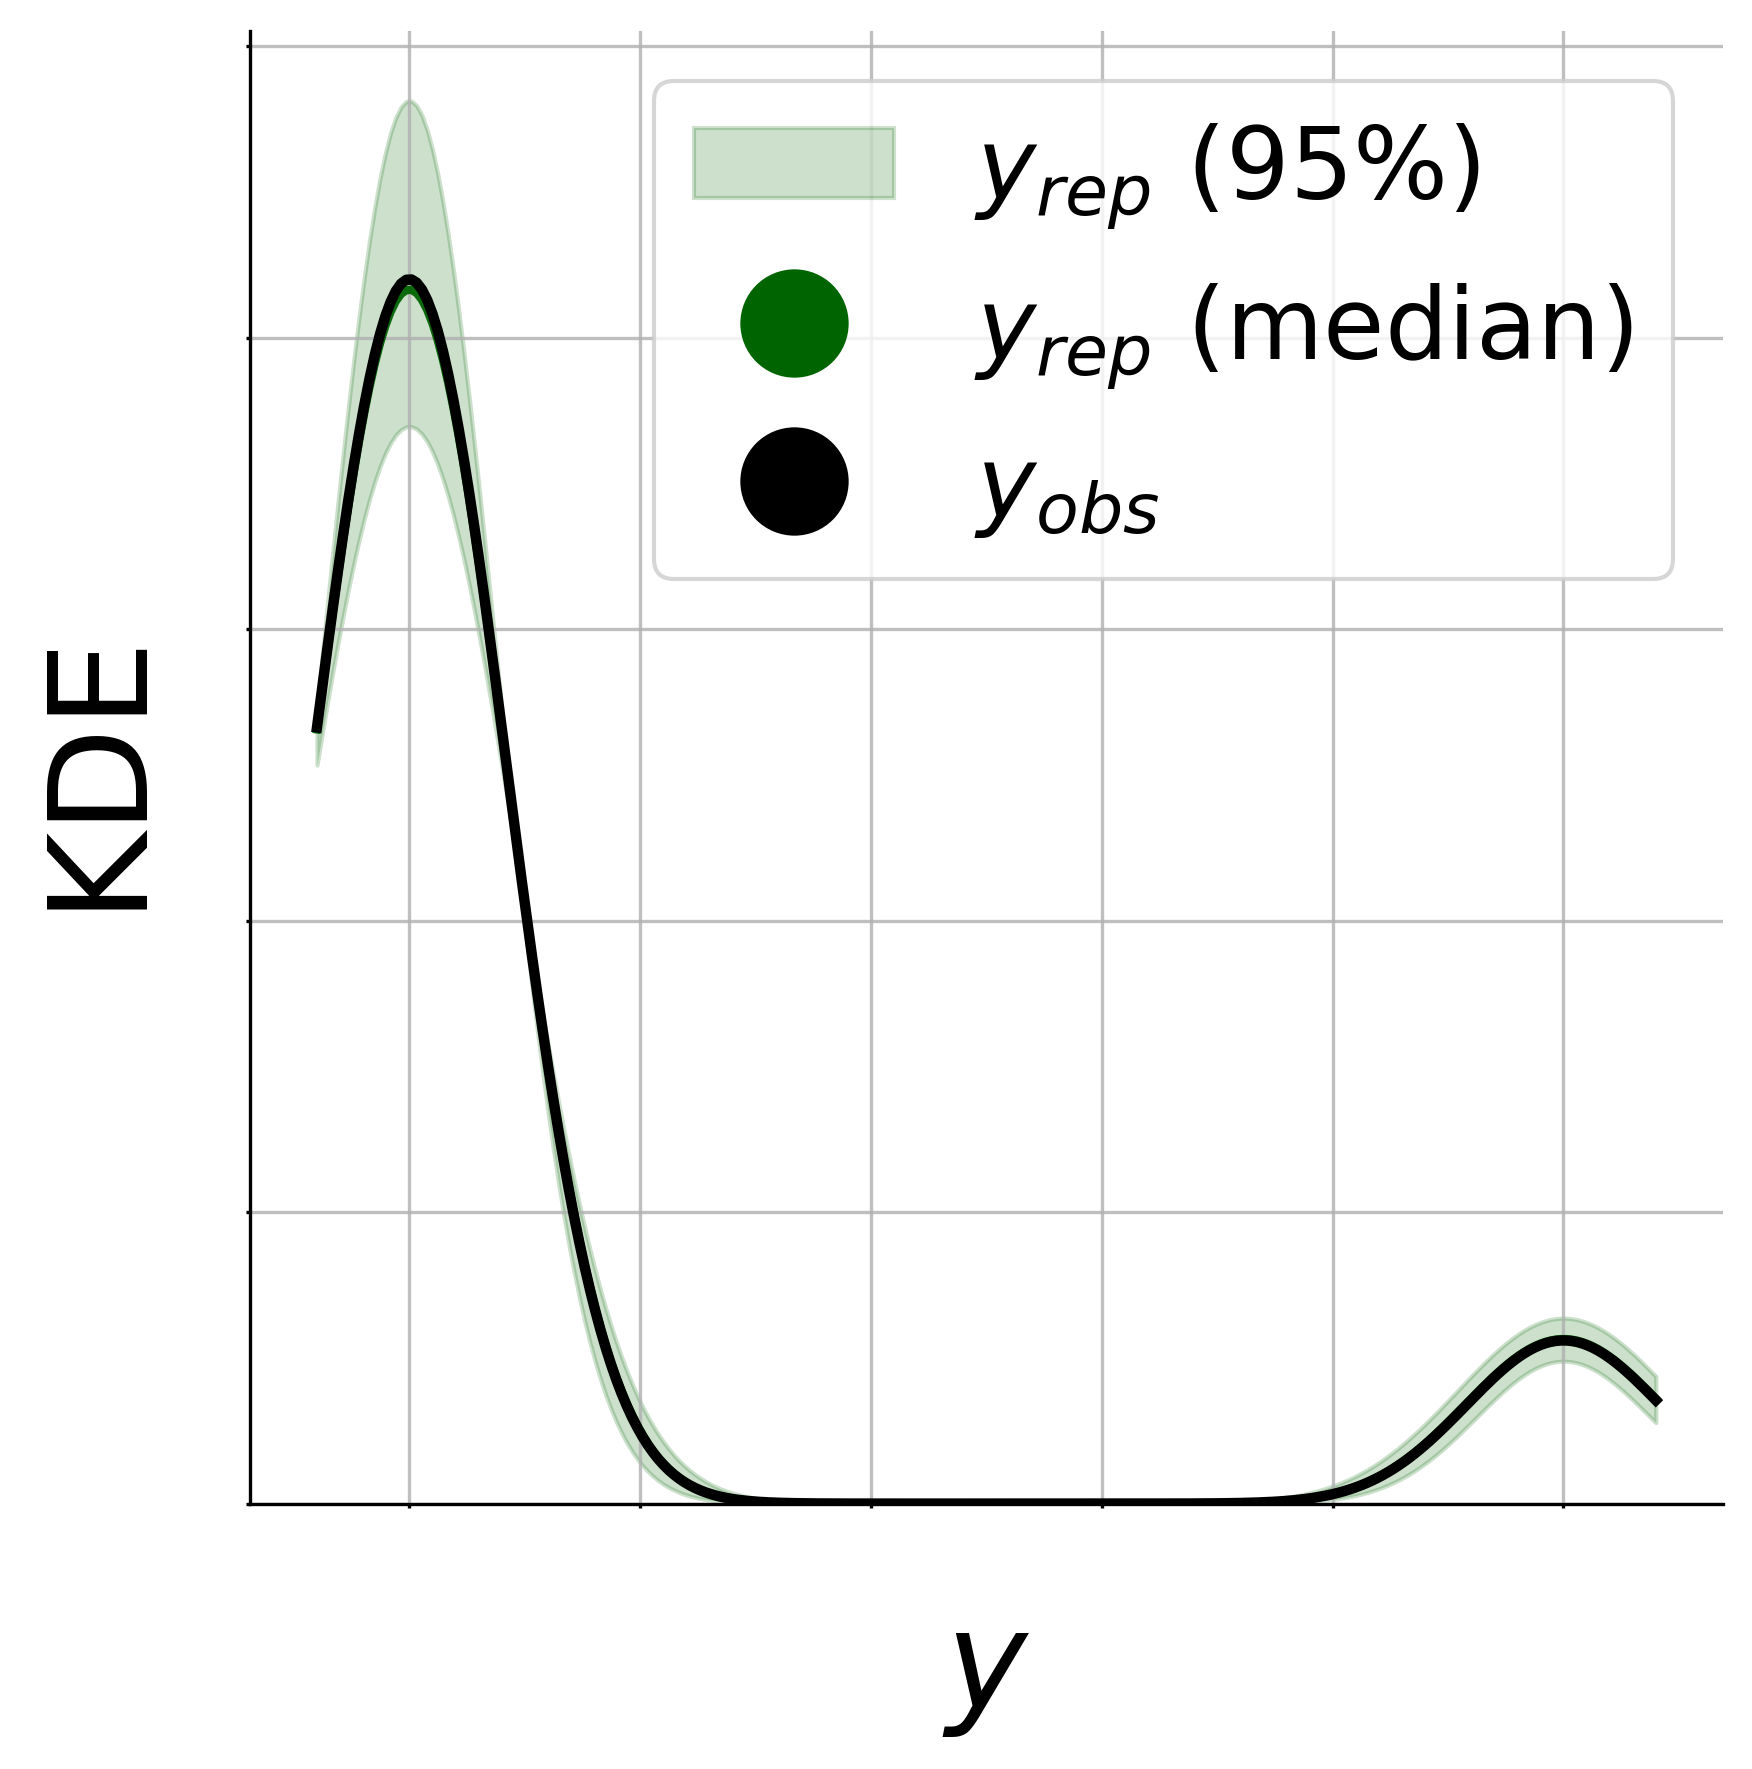

In [6]:
mb_bernoulli.plotPPD(result_cbpp)

## Poisson: Salamanders

`Salamanders` ([Price et al.](https://doi.org/10.1111/1365-2664.12585)) counts salamanders in
23 Appalachian streams, some of them below mountaintop-removal mines (`mined`), on four visits
for each of seven species. glmmTMB ships the data, but Rdatasets does not, so download the
`.rda` from a [pinned glmmTMB commit](https://github.com/glmmTMB/glmmTMB/raw/1db3b4692aa4c61ae5c9974b32b9f91555cf5f2c/glmmTMB/data/Salamanders.rda) and read it with `pyreadr`. `mined` and
`site` are R factors; cast them to `str`. `Wtemp`, the standardized water temperature, is kept
for a random slope of your own.

In [7]:
pyreadr.download_file('https://github.com/glmmTMB/glmmTMB/raw/1db3b4692aa4c61ae5c9974b32b9f91555cf5f2c/glmmTMB/data/Salamanders.rda', 'Salamanders.rda')
salamanders = pyreadr.read_r('Salamanders.rda')['Salamanders']
df_sal = salamanders[['count', 'mined', 'Wtemp', 'site']].astype({'mined': str, 'site': str})
print(f'{len(df_sal)} rows in {df_sal["site"].nunique()} sites')
df_sal.head()

644 rows in 23 sites


,count,mined,Wtemp,site
0,0,yes,-1.229379,VF-1
1,0,yes,0.084765,VF-2
2,0,yes,1.014176,VF-3
3,2,no,-3.023358,R-1
4,2,no,-0.144345,R-2


### Fit with the defaults

The formula is glmmTMB's simplest: a fixed effect of `mined` (`no` is the reference) and a random
intercept per site. The fit warns. The IMH chains accept few proposals (acceptance 0.17) and
revisit few distinct states, so the smallest ESS over the global parameters is 26, far below
150, and the refined sample can be too narrow where the network under-covers the posterior.
The warning lists the remedies: more draws, `random_walk=True`, or exact MCMC. On this dataset
more draws leave the ESS far below the threshold, which says that the network's proposal is too
narrow somewhere; only moves that step off it can repair that.

In [8]:
%%time
torch.manual_seed(0)
result_imh = mb_poisson.sample(df_sal, formula='count ~ mined + (1 | site)')

CPU times: user 351 ms, sys: 24.1 ms, total: 375 ms
Wall time: 270 ms


<timed exec>:2: UserWarning: IMH effective sample size is low for dataset(s) [0] (min bulk ESS over global parameters 26 < 150): the chains revisit few distinct states, and the refined sample can be too narrow. The ESS grows with n_samples, so re-run with more draws first; if it stays low, the flow under-covers the posterior there. Re-run with random_walk=True to continue the IMH with random-walk moves on the same target, or use exact MCMC (e.g. NUTS).


In [9]:
result_imh.routes

['poisson-small']

The fixed effects are on the log scale: the intercept is the log of the expected count at an
unmined site, and `mined_yes` the log of the ratio of the counts at mined and unmined sites, so
a posterior mean of −2.30 is a drop to a tenth.

In [10]:
print(mb_poisson.posteriorSummary(result_imh))

Formula:  count ~ mined + (1 | site)
n = 644   m = 23
Priors:
  Intercept ~ N(0, 2.5)
  mined_yes ~ N(0, 2.5)
  σ_Intercept ~ HN(2.5)

Fixed Effects:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |   P(>0) |   Contr. |
|-----------|--------|-------|--------|---------|---------|---------|----------|
| Intercept |  0.780 | 0.173 |  0.476 |   0.762 |   1.074 |   1.000 |    0.995 |
| mined_yes | -2.304 | 0.320 | -2.945 |  -2.307 |  -1.751 |   0.000 |    0.984 |

Standard Deviations:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |
|-----------|--------|-------|--------|---------|---------|
| Intercept |  0.685 | 0.185 |  0.446 |   0.653 |   1.201 |

draws = 1000   acceptance = 0.17   min ESS = 26   PSIS k̂ = 0.590 (refined)   MAP z = 0.4


### With random-walk moves

`random_walk=True` continues the IMH chains with random-walk Metropolis moves on the same
target, the marginal posterior of the global parameters. The moves can step off the network's
proposals, so they reach the regions a narrow proposal misses. They run only on the datasets
whose ESS fell below the threshold, so the flag doubles as a gate: where it stays shut, the
result equals IMH alone, which is why `01-quickstart` does not use them. One line reports where
they ran. The footer keeps the IMH chain's acceptance and ESS; the moves' own acceptance is in
`result.safeguards['random_walk_accept']`.

In [11]:
%%time
torch.manual_seed(0)
result_rw = mb_poisson.sample(
    df_sal, formula='count ~ mined + (1 | site)', random_walk=True, diagnostics=True
)

CPU times: user 1.01 s, sys: 76.4 ms, total: 1.09 s
Wall time: 763 ms


<timed exec>:2: UserWarning: Random-walk moves ran for dataset(s) [0] (IMH min bulk ESS 26).


In [12]:
print(mb_poisson.posteriorSummary(result_rw))

Formula:  count ~ mined + (1 | site)
n = 644   m = 23
Priors:
  Intercept ~ N(0, 2.5)
  mined_yes ~ N(0, 2.5)
  σ_Intercept ~ HN(2.5)

Fixed Effects:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |   P(>0) |   Contr. |
|-----------|--------|-------|--------|---------|---------|---------|----------|
| Intercept |  0.726 | 0.195 |  0.330 |   0.729 |   1.105 |   1.000 |    0.994 |
| mined_yes | -2.246 | 0.327 | -2.884 |  -2.247 |  -1.641 |   0.000 |    0.983 |

Standard Deviations:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |
|-----------|--------|-------|--------|---------|---------|
| Intercept |  0.679 | 0.166 |  0.430 |   0.647 |   1.073 |

draws = 1000   Deviance = 2.201   LOO-NLL = 1.729   Pareto k = 0.089   acceptance = 0.17   min ESS = 26   PSIS k̂ = 0.590 (refined)   MAP z = 0.4


### Against NUTS

The reference is PyMC's NUTS on the model metabeta fits: the same standardized design and the
same default priors, built by `metabeta.utils.pymc.buildPymc` from the research extra. Its
settings, convergence checks and intervals are recorded here, so the notebook runs without
PyMC. The wall time is from the laptop that produced the committed outputs.

In [13]:
nuts_run = pd.Series(
    {
        'chains': 4,
        'draws per chain': 1000,
        'tuning steps': 1000,
        'target_accept': 0.9,
        'divergences': 0,
        'max r-hat': 1.004,
        'min bulk ESS': 592,
        'wall time (s)': 2.3,
    },
    dtype=object,
)
nuts = pd.DataFrame(
    {'mean': [0.737, -2.270], '2.5%': [0.310, -2.965], '97.5%': [1.159, -1.640]},
    index=['Intercept', 'mined_yes'],
)
print(nuts_run.to_string())
nuts

chains                 4
draws per chain     1000
tuning steps        1000
target_accept        0.9
divergences            0
max r-hat          1.004
min bulk ESS         592
wall time (s)        2.3


,mean,2.5%,97.5%
Intercept,0.737,0.310,1.159
mined_yes,-2.270,-2.965,-1.640


### Intervals

The table puts the 95% intervals side by side: IMH alone, IMH with the moves, and NUTS.
`result.scale_info` maps the draws to the original scale, as the summaries do. The intercept's
interval is 0.70 of NUTS's width with IMH alone and 0.91 with the moves. The `mined` effect
barely moves: from −2.30 to −2.25, with NUTS at −2.27, and its width from 0.90 to 0.94 of
NUTS's. The moves widen the intervals where the network's proposal was too narrow and leave the
rest alone, at a fraction of the cost of NUTS.

In [14]:
def intervals(result):
    ffx = result.scale_info.to_original_scale(result.proposal.ffx[0])[:, :2].numpy()  # (S, 2)
    lo, hi = np.percentile(ffx, [2.5, 97.5], axis=0)
    return pd.DataFrame({'mean': ffx.mean(axis=0), '2.5%': lo, '97.5%': hi}, index=nuts.index)


table = pd.concat(
    {'IMH': intervals(result_imh), 'IMH + moves': intervals(result_rw), 'NUTS': nuts},
    names=['method', 'parameter'],
)
table = table.swaplevel().sort_index(level='parameter', sort_remaining=False)
table['95% width'] = table['97.5%'] - table['2.5%']
table['width / NUTS'] = table['95% width'] / table['95% width'].xs('NUTS', level='method')
table.round(2)

mean  2.5%  97.5%  95% width  width / NUTS
parameter method                                                 
Intercept IMH          0.78  0.48   1.07       0.60          0.70
          IMH + moves  0.73  0.33   1.11       0.78          0.91
          NUTS         0.74  0.31   1.16       0.85          1.00
mined_yes IMH         -2.30 -2.94  -1.75       1.19          0.90
          IMH + moves -2.25 -2.88  -1.64       1.24          0.94
          NUTS        -2.27 -2.96  -1.64       1.32          1.00

### Posterior predictive check

Counts pile up at zero and thin out to the right. The replicated counts put more mass at zero
and less at the small counts than the observed ones, and the observed tail runs further: the
data are overdispersed relative to a Poisson with a site intercept, which is why
[Brooks et al.](https://doi.org/10.32614/RJ-2017-066) move on to negative binomial and
zero-inflated models on these data. metabeta fits neither, so the check marks a limit of the
model, not of the sampler.

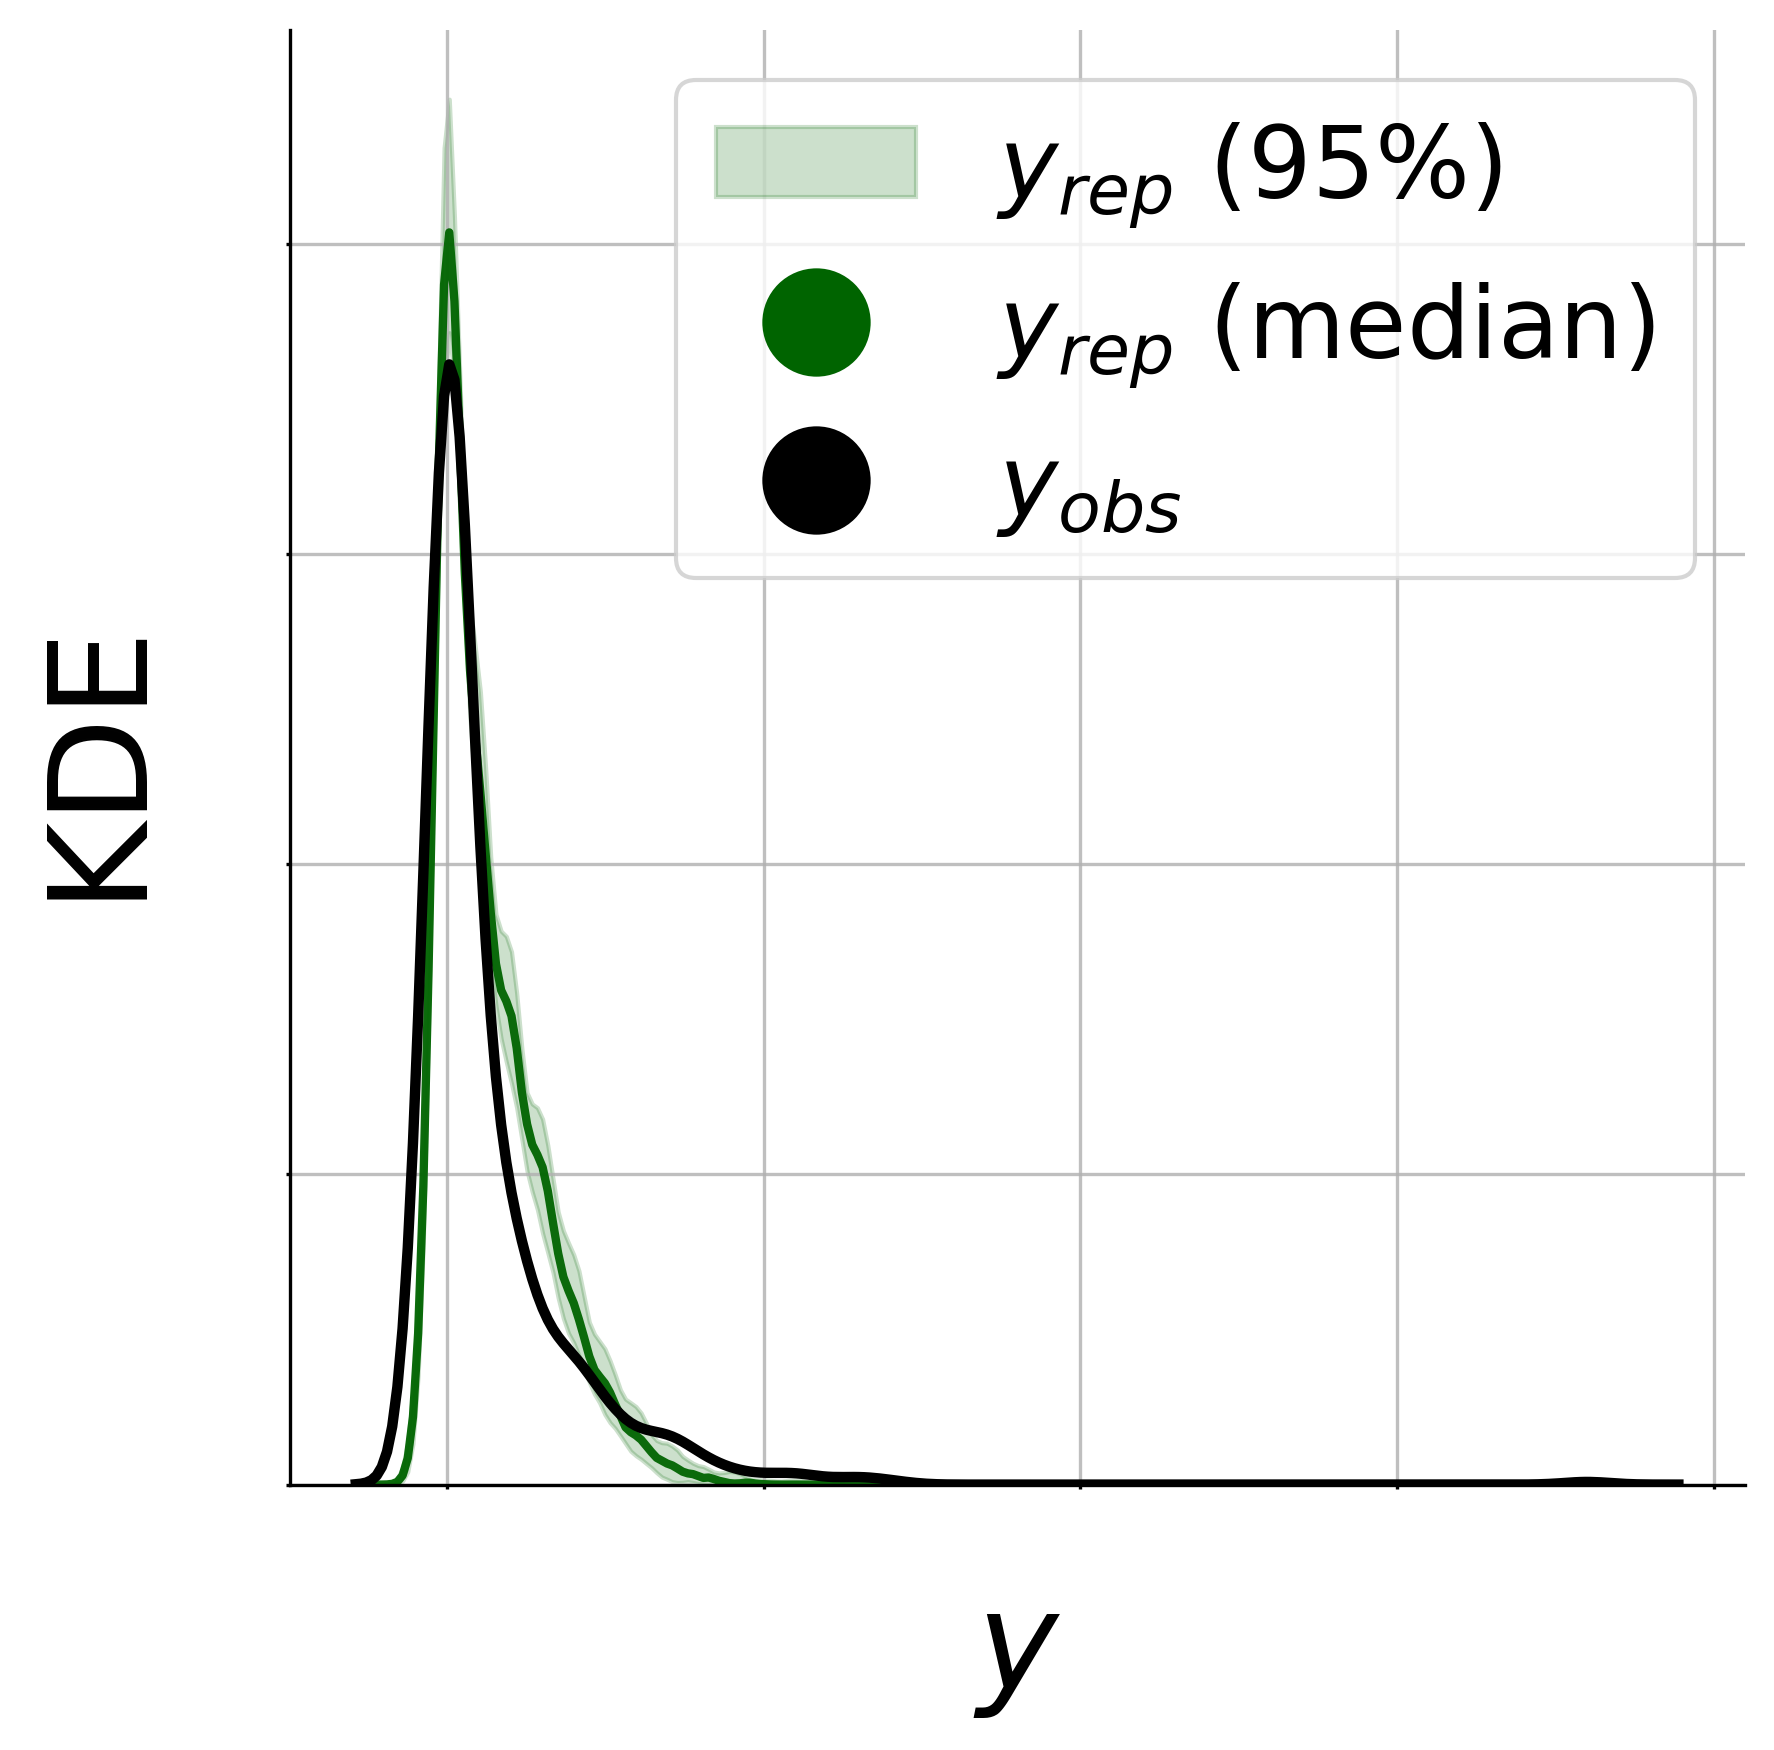

In [15]:
mb_poisson.plotPPD(result_rw)

## When to use the moves

`random_walk=True` is safe to pass by default: the moves run only where the ESS warning fires,
and they cost a few times the IMH alone. Where the ESS is far lower still, the moves-ran line
adds that they may not close the gap and says to check against exact MCMC. `03-priors` sets
your own priors and compares models with Bayes factors.